# Plots for SI

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

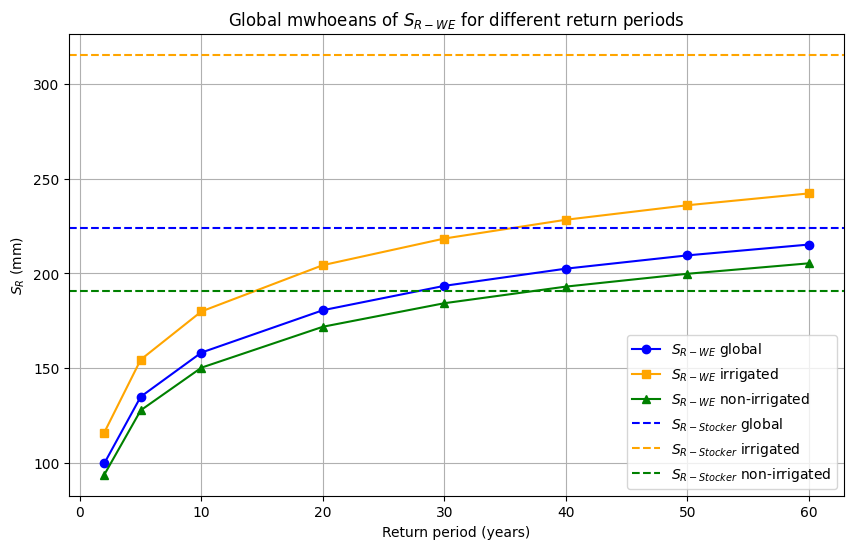

In [2]:
refGrid = xr.open_dataset('../data/SR-target/refGrid.nc')
stocker = xr.open_dataarray('../data-raw/SR/cwdx80.nc') # Stocker SR dataset
stocker = stocker.interp_like(refGrid, method='nearest') # limit Stocker to 74.4 N, which is the northernmost latitude in CRU20
# cru20_0p5 = xr.open_dataset('data/SR_alt/sr_cru20_0p5.nc') # CRU20 SR dataset, resampled to 0.5 degree resolution
#cropland_frac_0p05_da = xr.open_dataarray('../data/MergeStockerCRU/cropland_frac_0p05.nc')
irr_yr_frac_da = xr.open_dataarray('../data/MergeStockerCRU/irr_yr_frac.nc')
stocker_0p5 = stocker.coarsen(lat=10, lon=10, boundary='trim').mean()

# load all years into a dictionary
srCRU_dict = {}
for rp in [2,5,10,20,30,40,50,60]:
    srCRU = xr.open_dataarray('../data-raw/SR/Wang-Erlandsson-HESS2016/sr_cru_{}yrs.asc'.format(rp))
    srCRU = srCRU.rename({'x': 'lon', 'y': 'lat'}).drop_vars(['spatial_ref', 'band'])
    srCRU = srCRU.rename('srCRU_{}'.format(rp))
    srCRU = srCRU.interp_like(stocker_0p5, method='nearest')
    srCRU_dict[rp] = srCRU

# plot global mean of SR CRU for different return periods
# common mask for where all rp and stocker has valid data
common_mask = np.ones_like(stocker_0p5, dtype=bool)
for rp in srCRU_dict.keys():
    common_mask = common_mask & stocker_0p5.notnull() & srCRU_dict[rp].notnull()
# add a series for mean in irrigated areas as well, where mean is calculated as the global mean of (CRU20 * where irr_yr_frac > 0) for each return period
srCRU_means = {rp: srCRU_dict[rp].where(common_mask).weighted(np.cos(np.radians(srCRU_dict[rp].lat))).mean().item() for rp in srCRU_dict.keys()}
# calculate mean for irrigated areas

irr_yr_frac_aligned = irr_yr_frac_da.interp_like(stocker_0p5, method='nearest')
irr_srCRU_means = {rp: (srCRU_dict[rp] * xr.where(irr_yr_frac_aligned > 0, 1, np.nan)).where(common_mask).weighted(np.cos(np.radians((srCRU_dict[rp].lat)))).mean().item() for rp in srCRU_dict.keys()}
nonirr_srCRU_means = {rp: (srCRU_dict[rp] * xr.where(irr_yr_frac_aligned == 0, 1, np.nan)).where(common_mask).weighted(np.cos(np.radians((srCRU_dict[rp].lat)))).mean().item() for rp in srCRU_dict.keys()}

# add stocker global mean , irrigated mean and non-irrigated mean as horozontal lines
# use xarray weighted with cos(lat)
stocker_mean = stocker_0p5.where(common_mask).weighted(np.cos(np.radians(stocker_0p5.lat))).mean().item()
irr_stocker_mean = (stocker_0p5 * xr.where(irr_yr_frac_aligned > 0, 1, np.nan)).where(common_mask).weighted(np.cos(np.radians((stocker_0p5.lat)))).mean().item()
nonirr_stocker_mean = (stocker_0p5 * xr.where(irr_yr_frac_aligned == 0, 1, np.nan)).where(common_mask).weighted(np.cos(np.radians((stocker_0p5.lat)))).mean().item()

# create a new dataframe for plotting, with columns for return period, global mean, irrigated mean and non-irrigated mean
df_srWE = pd.DataFrame({
    'Return period (years)': list(srCRU_means.keys()),
    'Global': list(srCRU_means.values()),
    'Irrigated': list(irr_srCRU_means.values()),
    'Non-irrigated': list(nonirr_srCRU_means.values())
})

df_srStocker = pd.DataFrame({
    'Return period (years)': [80],
    'Global': [stocker_mean],
    'Irrigated': [irr_stocker_mean],
    'Non-irrigated': [nonirr_stocker_mean]
})

plt.figure(figsize=(10,6))
plt.plot(df_srWE['Return period (years)'], df_srWE['Global'], marker='o', label='$S_{R-WE}$ global', color='blue')
plt.plot(df_srWE['Return period (years)'], df_srWE['Irrigated'], marker='s', label='$S_{R-WE}$ irrigated', color='orange')
plt.plot(df_srWE['Return period (years)'], df_srWE['Non-irrigated'], marker='^', label='$S_{R-WE}$ non-irrigated', color='green')
plt.axhline(df_srStocker['Global'].iloc[0], color='blue', linestyle='--', label='$S_{R-Stocker}$ global')
plt.axhline(df_srStocker['Irrigated'].iloc[0], color='orange', linestyle='--', label='$S_{R-Stocker}$ irrigated')
plt.axhline(df_srStocker['Non-irrigated'].iloc[0], color='green', linestyle='--', label='$S_{R-Stocker}$ non-irrigated')

plt.xlabel('Return period (years)')
plt.ylabel('$S_R$ (mm)')
plt.title('Global mwhoeans of $S_{R-WE}$ for different return periods')
plt.grid()
plt.legend()
plt.show()

In [3]:
# calculate correlation between Stocker and each of the Wang-Erlandson SR datasets in the non-irrigated areas
# get pearson, spearman, RMSE, and KGE, for each return period, and store in a dictionary

from scipy.stats import spearmanr

# modified KGE using CV instead of std, and using the global mean of each dataset instead of the mean of the paired values, to avoid issues with nans and different spatial coverage between Stocker and CRU
def mod_kge(sim, obs):
    sim_mean = sim.mean()
    obs_mean = obs.mean()
    sim_cv = sim.std() / sim.mean() if sim.mean() != 0 else 0
    obs_cv = obs.std() / obs.mean() if obs.mean() != 0 else 0
    r = np.corrcoef(sim, obs)[0, 1]
    alpha = sim_cv / obs_cv if obs_cv != 0 else 0
    beta = sim_mean / obs_mean
    kge_value = 1 - np.sqrt((r - 1)**2 + (alpha - 1)**2 + (beta - 1)**2)
    return kge_value

irr_yr_frac_da_aligned = irr_yr_frac_da.interp_like(stocker_0p5, method='nearest')
correlations = {}
for rp, srCRU in srCRU_dict.items():
    # mask out irrigated areas using irr_yr_frac_da_0p05
    valid_mask = (irr_yr_frac_da_aligned == 0 & stocker_0p5.notnull() & srCRU.notnull())
    stocker_non_irrigated = stocker_0p5.where(valid_mask)
    srCRU_non_irrigated = srCRU.where(valid_mask)
    
    # calculate correlation between stocker_non_irrigated and srCRU_non_irrigated, ignoring nans
    valid_mask = np.isfinite(stocker_non_irrigated) & np.isfinite(srCRU_non_irrigated)

    # flatten and drop nan
    stocker_values = stocker_non_irrigated.where(valid_mask).values.flatten()
    srCRU_values = srCRU_non_irrigated.where(valid_mask).values.flatten()
    stocker_values = stocker_values[np.isfinite(stocker_values)]
    srCRU_values = srCRU_values[np.isfinite(srCRU_values)]

    pearson_correlation = np.corrcoef(stocker_values, srCRU_values)[0, 1]
    spearman_correlation = spearmanr(stocker_values, srCRU_values)[0]
    r2 = pearson_correlation**2
    rmse = np.sqrt(((stocker_values - srCRU_values)**2).mean())
    kge_value = mod_kge(stocker_values, srCRU_values)
    correlations[rp] = {'pearson': pearson_correlation.item(), 'spearman': spearman_correlation, 'r2': r2.item(), 'rmse': rmse.item(), 'kge': kge_value}

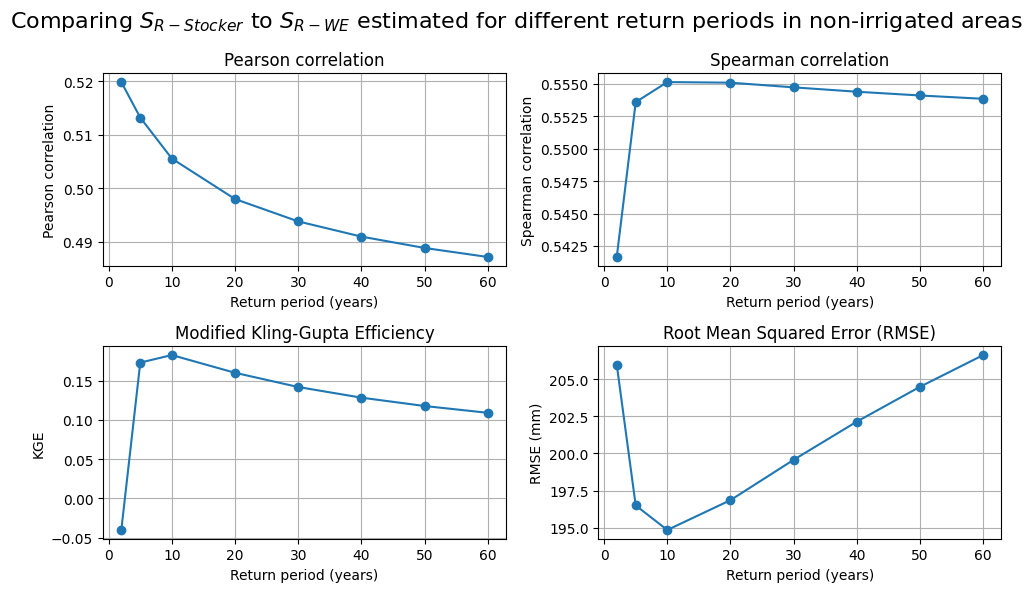

In [4]:
# advanced plot with pearson, spearman, r2 and rmse in subplots
plt.figure(figsize=(10,6))
# main title
plt.suptitle('Comparing $S_{R-Stocker}$ to $S_{R-WE}$ estimated for different return periods in non-irrigated areas', fontsize=16)
plt.subplot(2,2,1)
plt.plot(list(correlations.keys()), [v['pearson'] for v in correlations.values()], marker='o')
plt.xlabel('Return period (years)')
plt.ylabel('Pearson correlation')
plt.title('Pearson correlation')
plt.grid()
plt.subplot(2,2,2)
plt.plot(list(correlations.keys()), [v['spearman'] for v in correlations.values()], marker='o')
plt.xlabel('Return period (years)')
plt.ylabel('Spearman correlation')
plt.title('Spearman correlation')
plt.grid()
plt.subplot(2,2,3)
plt.plot(list(correlations.keys()), [v['kge'] for v in correlations.values()], marker='o')
plt.xlabel('Return period (years)')
plt.ylabel('KGE')
plt.title('Modified Kling-Gupta Efficiency')
plt.grid()
plt.subplot(2,2,4)
plt.plot(list(correlations.keys()), [v['rmse'] for v in correlations.values()], marker='o')
plt.xlabel('Return period (years)')
plt.ylabel('RMSE (mm)')
plt.title('Root Mean Squared Error (RMSE)')
plt.grid()
plt.tight_layout()
plt.show()